# Exploring Embeddings with Keras

In [204]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [205]:
import sys

sys.executable

'/home/thomas/Python/virtualenvs/uj_embeddings/bin/python'

In [206]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import pairwise_distances

In [207]:
#import keras
#from keras import layers
#from keras import ops

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
import math
import numpy as np
import pandas as pd
#from tensorflow import data as tf_data
#import matplotlib.pyplot as plt
from functools import partial

## Imports

In [ ]:
CSV_HEADER = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education_num",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "gender",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "native_country",
    "income_bracket",
]

train_data_url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
)
train_data = pd.read_csv(train_data_url, header=None, names=CSV_HEADER)

test_data_url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"
)
test_data = pd.read_csv(test_data_url, header=None, names=CSV_HEADER)

print(f"Train dataset shape: {train_data.shape}")
print(f"Test dataset shape: {test_data.shape}")

In [ ]:
test_data = test_data[1:]
test_data.income_bracket = test_data.income_bracket.apply(
    lambda value: value.replace(".", "")
)

In [ ]:
train_data_file = "train_data.csv"
test_data_file = "test_data.csv"

train_data.to_csv(train_data_file, index=False, header=False)
test_data.to_csv(test_data_file, index=False, header=False)


In [ ]:
# A list of the numerical feature names.
NUMERIC_FEATURE_NAMES = [
    "age",
    "education_num",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
]
# A dictionary of the categorical features and their vocabulary.
CATEGORICAL_FEATURES_WITH_VOCABULARY = {
    "workclass": sorted(list(train_data["workclass"].unique())),
    "education": sorted(list(train_data["education"].unique())),
    "marital_status": sorted(list(train_data["marital_status"].unique())),
    "occupation": sorted(list(train_data["occupation"].unique())),
    "relationship": sorted(list(train_data["relationship"].unique())),
    "race": sorted(list(train_data["race"].unique())),
    "gender": sorted(list(train_data["gender"].unique())),
    "native_country": sorted(list(train_data["native_country"].unique())),
}
# Name of the column to be used as instances weight.
WEIGHT_COLUMN_NAME = "fnlwgt"
# A list of the categorical feature names.
CATEGORICAL_FEATURE_NAMES = list(CATEGORICAL_FEATURES_WITH_VOCABULARY.keys())
# A list of all the input features.
FEATURE_NAMES = NUMERIC_FEATURE_NAMES + CATEGORICAL_FEATURE_NAMES
# A list of column default values for each feature.
COLUMN_DEFAULTS = [
    [0.0] if feature_name in NUMERIC_FEATURE_NAMES + [WEIGHT_COLUMN_NAME] else ["NA"]
    for feature_name in CSV_HEADER
]
# The name of the target feature.
TARGET_FEATURE_NAME = "income_bracket"
# A list of the labels of the target features.
TARGET_LABELS = [" <=50K", " >50K"]


In [ ]:
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
DROPOUT_RATE = 0.2
BATCH_SIZE = 265
NUM_EPOCHS = 15

NUM_TRANSFORMER_BLOCKS = 3  # Number of transformer blocks.
NUM_HEADS = 4  # Number of attention heads.
EMBEDDING_DIMS = 16  # Embedding dimensions of the categorical features.
MLP_HIDDEN_UNITS_FACTORS = [
    2,
    1,
]  # MLP hidden layer units, as factors of the number of inputs.
NUM_MLP_BLOCKS = 2  # Number of MLP blocks in the baseline model.


In [ ]:
target_label_lookup = layers.StringLookup(
    vocabulary=TARGET_LABELS, mask_token=None, num_oov_indices=0
)


def prepare_example(features, target):
    target_index = target_label_lookup(target)
    weights = features.pop(WEIGHT_COLUMN_NAME)
    return features, target_index, weights


lookup_dict = {}
for feature_name in CATEGORICAL_FEATURE_NAMES:
    vocabulary = CATEGORICAL_FEATURES_WITH_VOCABULARY[feature_name]
    # Create a lookup to convert a string values to an integer indices.
    # Since we are not using a mask token, nor expecting any out of vocabulary
    # (oov) token, we set mask_token to None and num_oov_indices to 0.
    lookup = layers.StringLookup(
        vocabulary=vocabulary, mask_token=None, num_oov_indices=0
    )
    lookup_dict[feature_name] = lookup


def encode_categorical(batch_x, batch_y, weights):
    for feature_name in CATEGORICAL_FEATURE_NAMES:
        batch_x[feature_name] = lookup_dict[feature_name](batch_x[feature_name])

    return batch_x, batch_y, weights


def get_dataset_from_csv(csv_file_path, batch_size=128, shuffle=False):
    dataset = (
        tf_data.experimental.make_csv_dataset(
            csv_file_path,
            batch_size=batch_size,
            column_names=CSV_HEADER,
            column_defaults=COLUMN_DEFAULTS,
            label_name=TARGET_FEATURE_NAME,
            num_epochs=1,
            header=False,
            na_value="?",
            shuffle=shuffle,
        )
        .map(prepare_example, num_parallel_calls=tf_data.AUTOTUNE, deterministic=False)
        .map(encode_categorical)
    )
    return dataset.cache()


In [ ]:
def run_experiment(
    model,
    train_data_file,
    test_data_file,
    num_epochs,
    learning_rate,
    weight_decay,
    batch_size,
):
    optimizer = keras.optimizers.AdamW(
        learning_rate=learning_rate, weight_decay=weight_decay
    )

    model.compile(
        optimizer=optimizer,
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[keras.metrics.BinaryAccuracy(name="accuracy")],
    )

    train_dataset = get_dataset_from_csv(train_data_file, batch_size, shuffle=True)
    validation_dataset = get_dataset_from_csv(test_data_file, batch_size)

    print("Start training the model...")
    history = model.fit(
        train_dataset, epochs=num_epochs, validation_data=validation_dataset
    )
    print("Model training finished")

    _, accuracy = model.evaluate(validation_dataset, verbose=0)

    print(f"Validation accuracy: {round(accuracy * 100, 2)}%")

    return history

In [ ]:
def create_model_inputs():
    inputs = {}
    for feature_name in FEATURE_NAMES:
        if feature_name in NUMERIC_FEATURE_NAMES:
            inputs[feature_name] = layers.Input(
                name=feature_name, shape=(), dtype="float32"
            )
        else:
            inputs[feature_name] = layers.Input(
                name=feature_name, shape=(), dtype="int32"
            )
    return inputs


In [ ]:
def encode_inputs(inputs, embedding_dims):
    encoded_categorical_feature_list = []
    numerical_feature_list = []

    for feature_name in inputs:
        if feature_name in CATEGORICAL_FEATURE_NAMES:
            vocabulary = CATEGORICAL_FEATURES_WITH_VOCABULARY[feature_name]
            # Create a lookup to convert a string values to an integer indices.
            # Since we are not using a mask token, nor expecting any out of vocabulary
            # (oov) token, we set mask_token to None and num_oov_indices to 0.

            # Convert the string input values into integer indices.

            # Create an embedding layer with the specified dimensions.
            embedding = layers.Embedding(
                input_dim=len(vocabulary), output_dim=embedding_dims
            )

            # Convert the index values to embedding representations.
            encoded_categorical_feature = embedding(inputs[feature_name])
            encoded_categorical_feature_list.append(encoded_categorical_feature)

        else:
            # Use the numerical features as-is.
            numerical_feature = ops.expand_dims(inputs[feature_name], -1)
            numerical_feature_list.append(numerical_feature)

    return encoded_categorical_feature_list, numerical_feature_list


In [ ]:
def create_mlp(hidden_units, dropout_rate, activation, normalization_layer, name=None):
    mlp_layers = []
    for units in hidden_units:
        mlp_layers.append(normalization_layer())
        mlp_layers.append(layers.Dense(units, activation=activation))
        mlp_layers.append(layers.Dropout(dropout_rate))

    return keras.Sequential(mlp_layers, name=name)


In [ ]:
def create_tabtransformer_classifier(
    num_transformer_blocks,
    num_heads,
    embedding_dims,
    mlp_hidden_units_factors,
    dropout_rate,
    use_column_embedding=False,
):
    # Create model inputs.
    inputs = create_model_inputs()
    # encode features.
    encoded_categorical_feature_list, numerical_feature_list = encode_inputs(
        inputs, embedding_dims
    )
    # Stack categorical feature embeddings for the Tansformer.
    encoded_categorical_features = ops.stack(encoded_categorical_feature_list, axis=1)
    # Concatenate numerical features.
    numerical_features = layers.concatenate(numerical_feature_list)

    # Add column embedding to categorical feature embeddings.
    if use_column_embedding:
        num_columns = encoded_categorical_features.shape[1]
        column_embedding = layers.Embedding(
            input_dim=num_columns, output_dim=embedding_dims
        )
        column_indices = ops.arange(start=0, stop=num_columns, step=1)
        encoded_categorical_features = encoded_categorical_features + column_embedding(
            column_indices
        )

    # Create multiple layers of the Transformer block.
    for block_idx in range(num_transformer_blocks):
        # Create a multi-head attention layer.
        attention_output = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embedding_dims,
            dropout=dropout_rate,
            name=f"multihead_attention_{block_idx}",
        )(encoded_categorical_features, encoded_categorical_features)
        # Skip connection 1.
        x = layers.Add(name=f"skip_connection1_{block_idx}")(
            [attention_output, encoded_categorical_features]
        )
        # Layer normalization 1.
        x = layers.LayerNormalization(name=f"layer_norm1_{block_idx}", epsilon=1e-6)(x)
        # Feedforward.
        feedforward_output = create_mlp(
            hidden_units=[embedding_dims],
            dropout_rate=dropout_rate,
            activation=keras.activations.gelu,
            normalization_layer=partial(
                layers.LayerNormalization, epsilon=1e-6
            ),  # using partial to provide keyword arguments before initialization
            name=f"feedforward_{block_idx}",
        )(x)
        # Skip connection 2.
        x = layers.Add(name=f"skip_connection2_{block_idx}")([feedforward_output, x])
        # Layer normalization 2.
        encoded_categorical_features = layers.LayerNormalization(
            name=f"layer_norm2_{block_idx}", epsilon=1e-6
        )(x)

    # Flatten the "contextualized" embeddings of the categorical features.
    categorical_features = layers.Flatten()(encoded_categorical_features)
    # Apply layer normalization to the numerical features.
    numerical_features = layers.LayerNormalization(epsilon=1e-6)(numerical_features)
    # Prepare the input for the final MLP block.
    features = layers.concatenate([categorical_features, numerical_features])

    # Compute MLP hidden_units.
    mlp_hidden_units = [
        factor * features.shape[-1] for factor in mlp_hidden_units_factors
    ]
    # Create final MLP.
    features = create_mlp(
        hidden_units=mlp_hidden_units,
        dropout_rate=dropout_rate,
        activation=keras.activations.selu,
        normalization_layer=layers.BatchNormalization,
        name="MLP",
    )(features)

    # Add a sigmoid as a binary classifer.
    outputs = layers.Dense(units=1, activation="sigmoid", name="sigmoid")(features)
    model = keras.Model(inputs=inputs, outputs=outputs)
    return model


tabtransformer_model = create_tabtransformer_classifier(
    num_transformer_blocks=NUM_TRANSFORMER_BLOCKS,
    num_heads=NUM_HEADS,
    embedding_dims=EMBEDDING_DIMS,
    mlp_hidden_units_factors=MLP_HIDDEN_UNITS_FACTORS,
    dropout_rate=DROPOUT_RATE,
)

print("Total model weights:", tabtransformer_model.count_params())
keras.utils.plot_model(tabtransformer_model, show_shapes=True, rankdir="LR")

In [ ]:
history = run_experiment(
    model=tabtransformer_model,
    train_data_file=train_data_file,
    test_data_file=test_data_file,
    num_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    batch_size=BATCH_SIZE,
)

# Microcrédito

In [2]:
['cpf9_espec',
 'id_eq3_espec',
 'cnpj_espec',
 'status_espec',
 'ano_mes_dia',
 'qtde_sub',
 'ult_ref_reneg',
 'flag pjampliada', 
 'qtd contratos',
 'qtd cntrt novo',
 'qtd cntrt renov int',
 'qtd_cntrt_renov merc',
 'qtd cntrts_en aberto',
 'qtd_cntrt_reneg',
 'qtd_fpd_reneg',
 'qtd cntrts pivo', 
 'qtd_cntrts_app', 
 'avg_idade_clientes',
 'qtd_cntrts_sld_pos_bc',
 'avg_mob_quit_cntrt', 
 'avg plano_cntrt', 
 'rz_vlr_entregue_c0c1',
 'rz_panis_pa',
 'rz_entregue_pa',
 'rz_entregue_panis',
 'avg_saldo_em_aberto_parc',
 'pct_cntrt_app',
 'pct_cntrts_reneg']

['cpf9_espec',
 'id_eq3_espec',
 'cnpj_espec',
 'status_espec',
 'ano_mes_dia',
 'qtde_sub',
 'ult_ref_reneg',
 'flag pjampliada',
 'qtd contratos',
 'qtd cntrt novo',
 'qtd cntrt renov int',
 'qtd_cntrt_renov merc',
 'qtd cntrts_en aberto',
 'qtd_cntrt_reneg',
 'qtd_fpd_reneg',
 'qtd cntrts pivo',
 'qtd_cntrts_app',
 'avg_idade_clientes',
 'qtd_cntrts_sld_pos_bc',
 'avg_mob_quit_cntrt',
 'avg plano_cntrt',
 'rz_vlr_entregue_c0c1',
 'rz_panis_pa',
 'rz_entregue_pa',
 'rz_entregue_panis',
 'avg saldo_em_aberto_parc',
 'pct_cntrt_app',
 'pct_cntrts_reneg']

- CONSIGNADO
    - Mix de propostas      -> Propostas por GH (2305) (Todos SPI cujas empresas possuem convênio com o banco (nrregra in ('OP','EP')). Propostas APROVADAS = quem possui PA no público acima)
    - Mix de contratação    -> Contratos por GH (2306)
    - Mix de inadimplência  -> Bad por GH
    * No mix de contratação, devemos utilizar o mesmo público de propostas como denominador, ou levamos em conta somente a referência?
    * No mix de contratação, utilizamos somente os contratos internos?
    * No mix de inadimplência, 100% interno? ou 50% 50% com mercado? 
      
- IMOB
    - Mix de propostas      -> Propostas por GH (2303)
    - Mix de contratação    -> Contratos por GH (2304)
    - Mix de inadimplência  -> Bad por GH
 


- PROPOSTAS
  - CONSIG: Cruzar as bases de produto (que identificam o público SPI de empresas conveniadas) com a base do modelo (GH)
  - IMOB: Cruzar base de propostas do produto (SAS, csv) com a base do modelo (GH)
 
- APROVAÇÃO
  - CONSIG: Cruzar a base de propostas acima (já marcada com GH do modelo) com a de produtos (que marcam o PA)
  - IMOB: A base de propostas já traz info de decisao
 
- CONTRATAÇÂO
  - CONSIG: Cruzar a base de aprovação acima (com GH e decisão de proposta) com a base do FOUCAULT CONTRATAÇÃO
  - IMOB: Cruzar a base de propostas acima (com GH e decisão de proposta) com a base do FOUCAULT CONTRATAÇÃO
 
- INADIMPLENCIA
  - CONSIG: Cruzar as bases de contratação acima (com GH, decisão de proposta e info de contratação) com as bases do FOUCAULT PD ITAU e PD MERC
  - IMOB: Cruzar as bases de contratação acima (com GH, decisão de proposta e info de contratação) com as bases do FOUCAULT PD ITAU e PD MERC

In [ ]:
politica_micro = ['Novos','Renov_Interna','Renov_Mercado']

- Acrescentar ao processo, join com a tabela de contratos
  - [ ] Cruzamento com modelo eleito PF (Polaris/VPRO)
  - [ ] Cruzamento com Meridian Microcredito (Capivara)
 
- GRUPO POLARIS
  - VP1: A1 - C3
  - VP2: C4 - D1
  - VP3: D2 - D4
  - VP4: E1 - E2
  - VP5: E3 - E4
  - VP6: F1
  - VP7: F2
  - VP8: F3 - f4

In [5]:
grupo_polaris = {
    'VP1': ['A1','A2','A3','B1','B2','B3','B4','C1','C2','C3'],
    'VP2': ['C4','D1'],
    'VP3': ['D2','D3','D4'],
    'VP4': ['E1','E2'],
    'VP5': ['E3','E4'],
    'VP6': ['F1'],
    'VP7': ['F2'],
    'VP8': ['F3','F4']
}

grupo_polaris
# conditions = [full_table.rating_polaris.isin(v) for k,v in grupo_polaris.items()]
# choices = [k for k,_ in grupo_polaris.items()]

# full_table['grupo_polaris'] == np.select(conditions, choices)

{'VP1': ['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'B4', 'C1', 'C2', 'C3'],
 'VP2': ['C4', 'D1'],
 'VP3': ['D2', 'D3', 'D4'],
 'VP4': ['E1', 'E2'],
 'VP5': ['E3', 'E4'],
 'VP6': ['F1'],
 'VP7': ['F2'],
 'VP8': ['F3', 'F4']}

In [16]:
grupo_polaris_hexagono = np.array([
    ['VPH1']*5,
    ['VPH1']*3 + ['VPH2']*2,
    ['VPH1']*2 + ['VPH2']*1 + ['VPH3']*2,
    ['VPH2']*2 + ['VPH3']*1 + ['VPH4']*2,
    ['VPH3']*2 + ['VPH4']*2 + ['VPH5']*1,
    ['VPH4']*2 + ['VPH5']*3,
    ['VPH5']*3 + ['VPH7']*2,
    ['VPH6']*2 + ['VPH7']*1 + ['VPH8']*2
])

df_vph = pd.DataFrame(grupo_polaris_hexagono, index=list(grupo_polaris.keys()), columns=[x for x in range(1,6)])
df_vph

,1,2,3,4,5
VP1,VPH1,VPH1,VPH1,VPH1,VPH1
VP2,VPH1,VPH1,VPH1,VPH2,VPH2
VP3,VPH1,VPH1,VPH2,VPH3,VPH3
VP4,VPH2,VPH2,VPH3,VPH4,VPH4
VP5,VPH3,VPH3,VPH4,VPH4,VPH5
VP6,VPH4,VPH4,VPH5,VPH5,VPH5
VP7,VPH5,VPH5,VPH5,VPH7,VPH7
VP8,VPH6,VPH6,VPH7,VPH8,VPH8


In [12]:
df_vph.at['VP8',1]

'VPH6'

In [31]:
grupo_risco_meridian = np.array([
    ['GRM1']*4 + ['GRM2']*2 + ['GRM4'] + ['GRM5']*2,
    ['GRM1']*1 + ['GRM2']*3 + ['GRM3']*2 + ['GRM4']*1 + ['GRM5']*2,
    ['GRM2']*3 + ['GRM3']*2 + ['GRM4']*2 + ['GRM5']*2,
    ['GRM3']*4 + ['GRM4']*3 + ['GRM5']*2,
    ['GRM4']*5 + ['GRM5']*4,
    ['GRM5']*5 + ['GRM6']*4,
    ['GRM6']*7 + ['GRM7']*2,
    ['GRM6']*5 + ['GRM7']*4
    
    
])

df_grm = pd.DataFrame(grupo_risco_meridian, index=np.sort(pd.unique(df_vph.values.ravel())), columns=[x for x in range(1,10)])
df_grm

,1,2,3,4,5,6,7,8,9
VPH1,GRM1,GRM1,GRM1,GRM1,GRM2,GRM2,GRM4,GRM5,GRM5
VPH2,GRM1,GRM2,GRM2,GRM2,GRM3,GRM3,GRM4,GRM5,GRM5
VPH3,GRM2,GRM2,GRM2,GRM3,GRM3,GRM4,GRM4,GRM5,GRM5
VPH4,GRM3,GRM3,GRM3,GRM3,GRM4,GRM4,GRM4,GRM5,GRM5
VPH5,GRM4,GRM4,GRM4,GRM4,GRM4,GRM5,GRM5,GRM5,GRM5
VPH6,GRM5,GRM5,GRM5,GRM5,GRM5,GRM6,GRM6,GRM6,GRM6
VPH7,GRM6,GRM6,GRM6,GRM6,GRM6,GRM6,GRM6,GRM7,GRM7
VPH8,GRM6,GRM6,GRM6,GRM6,GRM6,GRM7,GRM7,GRM7,GRM7


In [32]:
grupo_risco_renovacao = np.array([
    ['GRR1']*2 + ['GRR2']*7,
    ['GRR1']*1 + ['GRR2']*1 + ['GRR3']*4 + ['GRR4']*3,
    ['GRR2']*2 + ['GRR3']*3 + ['GRR4']*4,
    ['GRR3']*2 + ['GRR4']*3 + ['GRR5']*1 + ['GRR6']*3,
    ['GRR4']*2 + ['GRR5']*4 + ['GRR6']*3,
    ['GRR4']*2 + ['GRR5']*4 + ['GRR6']*3,
    ['GRR4']*2 + ['GRR5']*4 + ['GRR6']*3,
    ['GRR4']*2 + ['GRR5']*2 + ['GRR6']*5    
])

df_grr = pd.DataFrame(grupo_risco_renovacao, index=list(grupo_polaris.keys()), columns=[x for x in range(1,10)])
df_grr

,1,2,3,4,5,6,7,8,9
VP1,GRR1,GRR1,GRR2,GRR2,GRR2,GRR2,GRR2,GRR2,GRR2
VP2,GRR1,GRR2,GRR3,GRR3,GRR3,GRR3,GRR4,GRR4,GRR4
VP3,GRR2,GRR2,GRR3,GRR3,GRR3,GRR4,GRR4,GRR4,GRR4
VP4,GRR3,GRR3,GRR4,GRR4,GRR4,GRR5,GRR6,GRR6,GRR6
VP5,GRR4,GRR4,GRR5,GRR5,GRR5,GRR5,GRR6,GRR6,GRR6
VP6,GRR4,GRR4,GRR5,GRR5,GRR5,GRR5,GRR6,GRR6,GRR6
VP7,GRR4,GRR4,GRR5,GRR5,GRR5,GRR5,GRR6,GRR6,GRR6
VP8,GRR4,GRR4,GRR5,GRR5,GRR6,GRR6,GRR6,GRR6,GRR6


MATRIZES DE APROVAÇAO

In [62]:
class_espec = ['aam','aaa','bbb','ccc','ddd','hhh','ppp']

NOVOS

In [63]:
n_class_espec = len(class_espec)
n_grps_grm = len(pd.unique(df_grm.values.ravel()))

mat_aprov_novos = pd.DataFrame(np.ones((n_grps_grm,n_class_espec)), index=np.sort(pd.unique(df_grm.values.ravel())), columns=class_espec)
novos_neg = [('GRM3','ddd'), 
             ('GRM4','ccc'), ('GRM4','ddd'), 
             ('GRM5','bbb'), ('GRM5','ccc'), ('GRM5','ddd'),
             ('GRM6','aaa'), ('GRM6','bbb'), ('GRM6','ccc'), ('GRM6','ddd'), ('GRM6','hhh'), ('GRM6','ppp'),
             ('GRM7','aam'), ('GRM7','aaa'), ('GRM7','bbb'), ('GRM7','ccc'), ('GRM7','ddd'), ('GRM7','hhh'), ('GRM7','ppp')]

for grm, clasf in novos_neg:
    mat_aprov_novos.loc[grm,clasf] = 0

mat_aprov_novos

,aam,aaa,bbb,ccc,ddd,hhh,ppp
GRM1,1.0,1.0,1.0,1.0,1.0,1.0,1.0
GRM2,1.0,1.0,1.0,1.0,1.0,1.0,1.0
GRM3,1.0,1.0,1.0,1.0,0.0,1.0,1.0
GRM4,1.0,1.0,1.0,0.0,0.0,1.0,1.0
GRM5,1.0,1.0,0.0,0.0,0.0,1.0,1.0
GRM6,1.0,0.0,0.0,0.0,0.0,0.0,0.0
GRM7,0.0,0.0,0.0,0.0,0.0,0.0,0.0


RENOVACAO INTERNA

In [64]:
pd.unique(df_grr.values.ravel())

array(['GRR1', 'GRR2', 'GRR3', 'GRR4', 'GRR5', 'GRR6'], dtype=object)

In [65]:
n_class_espec, n_grps_grr

(7, 6)

In [66]:
len(class_espec)

7

In [67]:
n_class_espec = len(class_espec)
n_grps_grr = len(pd.unique(df_grr.values.ravel()))

mat_aprov_renov_int = pd.DataFrame(np.ones((n_grps_grr,n_class_espec)), 
                                   index=np.sort(pd.unique(df_grr.values.ravel())), 
                                   columns=class_espec)
renov_int_neg = [('GRR6','ccc'), ('GRR6','ddd')]

for grr, clasf in renov_int_neg:
    mat_aprov_renov_int.loc[grr,clasf] = 0

mat_aprov_renov_int.astype(bool)

,aam,aaa,bbb,ccc,ddd,hhh,ppp
GRR1,True,True,True,True,True,True,True
GRR2,True,True,True,True,True,True,True
GRR3,True,True,True,True,True,True,True
GRR4,True,True,True,True,True,True,True
GRR5,True,True,True,True,True,True,True
GRR6,True,True,True,False,False,True,True


In [55]:
np.ones((n_grps_grr,n_class_espec))

array([[1., 1., 1.],
       [1., 1., 1.],
       [1., 1., 1.],
       [1., 1., 1.],
       [1., 1., 1.],
       [1., 1., 1.]])

In [ ]:
full_table.politica_micro

In [ ]:
conditions = [arr1 > 2, arr2 < 9]
choices = [arr1, arr2 * 2]

result = np.select(conditions, choices, default=0)

- Propostas
  - Hexagono
  - Rating Polaris
  - Rating Meridian
  - Classificação do espec
  - Bad
 
- Métricas
  - Propostas aceitas/negadas
  - Propostas aceitas: calcular bad
  - Propostas negadas: verificar se houve contratação no mercado e, caso sim, marcar bad
 

- Determinar ponto de corte do score que mantém a média da bad no geral

- Ao determinar os cut points dos grupos de classificação, manter a mesma proporção de propostas aceitas/negadas? Ou manter a inadimplência (indicadores NPL e FPD) de cada classificação nos mesmos níveis?

In [ ]:
- Marca propostas aprovadas
    - Calcula bad
- Marca propostas negadas
    - Verifica contratação no mercado
    - Calcula bad mercado

- Marca a nova classificação dos especs
- Marca propostas que teriam sido aprovadas
    - Calcula bad
    - Verifica bad das propostas SWAP IN
- Marca propostas que teriam sido negadas
    - Verifica bad das propostas SWAP OUT (total e out)

- Tirar a duplicidade da base de propostas
  - Cruzar a base de contratos (cpf cliente, safra, valor) (LEFT JOIN) com a de propostas, pegando ID de transacao
  - Exclui da base inicial de pŕopostas todos os IDs transação já verificados na base de contratos
  - Da base completa de contratos: filtra cpf e safra sem duplicidade
  - Exclui da base inicial de propostas os casos acima
  - Na base de propostas restante: priorizar (cpf, safra) de quem possui proposta aceita

In [ ]:
espec_mcrcrdt_contratos.columns

In [ ]:
espec_mcrcrdt_contratos['cpf_cliente'] = espec_mcrcrdt_contratos.cpf_cliente
espec_mcrcrdt_contratos['cpf_espec'] = espec_mcrcrdt_contratos.cpf_espec
espec_mcrcrdt_contratos['classificacao_espec'] = espec_mcrcrdt_contratos.classificacao_espec
espec_mcrcrdt_contratos['safra'] = espec_mcrcrdt_contratos.safra
espec_mcrcrdt_contratos['valor'] = espec_mcrcrdt_contratos.valor

In [ ]:
espec_mcrcrdt_propostas.columns

In [ ]:
espec_mcrcrdt_propostas['cpf_cliente'] = espec_mcrcrdt_propostas.cpf_cliente
espec_mcrcrdt_propostas['cpf_espec'] = espec_mcrcrdt_propostas.cpf_espec
espec_mcrcrdt_propostas['classificacao_espec'] = espec_mcrcrdt_propostas.classificacao_espec
espec_mcrcrdt_propostas['safra'] = espec_mcrcrdt_propostas.safra
espec_mcrcrdt_propostas['valor'] = espec_mcrcrdt_propostas.valor

### Identifica contratos na base de proposta

In [ ]:
join_cols = ['cpf_cliente', 'cpf_espec', 'classificacao_espec','safra', 'valor']

In [ ]:
join_prop_cntrt = espec_mcrcrdt_contratos[join_cols].merge(espec_mcrcrdt_propostas[join_cols + ['id_transacao']],
                                                          how='inner',
                                                          on=join_cols)

In [ ]:
filtro_prop1 = list(join_prop_cntrt.id_transacao)

### Identifica CPFs com contratos ausentes da base de proposta

In [ ]:
pk = ['cpf_cliente', 'safra'] 

In [ ]:
clientes_contratos = espec_mcrcrdt_contratos[pk].drop_duplicates()

In [ ]:
filtro_prop2 = list(espec_mcrcrdt_propostas[espec_mcrcrdt_propostas.set_index(pk).index.isin(clientes_contratos.set_index(pk).index)].id_transacao)

### Retira as propostas acima da base

In [ ]:
filtro_props = list(set(filtro_prop1+filtro_prop2))

In [ ]:
espec_mcrcrdt_prop_filtr = espec_mcrcrdt_propostas[~(espec_mcrcrdt_propostas.id_transacao.isin(filtro_props))]

### Prioriza as prop restantes por prop aceita

In [ ]:
espec_mcrcrdt_prop_ddup = espec_mcrcrdt_prop_filtr.sort_values(by=['cpf_cliente', 'safra','decisao_final'],na_position='last', ascending=[True,True,True])./
                                        drop_duplicates(subset=['cpf_cliente','safra'])

In [ ]:
espec_mcrcrdt_prop_ddup.shape, espec_mcrcrdt_prop_ddup[['cpf_cliente', 'safra']].drop_duplicates().shape 

In [ ]:
filtro_prop3 = list(espec_mcrcrdt_prop_ddup.id_transacao)

In [ ]:
ids_transac_filtr = list(set(filtro_prop1 + filro_prop3))

In [ ]:
base_final_propostas = espec_mcrcrdt_propostas[espec_mcrcrdt_propostas.id_transacao.isin(ids_transac_filtr)]

In [ ]:
conditions = [full_table.rating_polaris.isin(v) for k,v in grupo_polaris.items()]
choices = [k for k,_ in grupo_polaris.items()]

full_table['grupo_polaris'] == np.select(conditions, choices)


cond_pol_ctrt_novo = base_final_propostas.politica_micro == 'Novos'
cond_pol_ctrt_renov_int = base_final_propostas.politica_micro == 'Renovacao_Interna'clclaro_naoaro_nao
cond_pol_ctrt_renov_mer = base_final_propostas.politica_micro == 'Renovacao_Mercado'

cond_grm7 = base_final_propostas.grm == 7
cond_grm6 = base_final_propostas.grm == 6
cond_grm5 = base_final_propostas.grm == 5
cond_grm4 = base_final_propostas.grm == 4
cond_grm3 = base_final_propostas.grm == 3

cond_grr6 = base_final_propostas.grr == 6
cond_grr5 = base_final_propostas.grr == 5
cond_grr4 = base_final_propostas.grr == 4

cond_class_espec_am = base_final_propostas.classif_espec == 'aam'
cond_class_espec_a = base_final_propostas.classif_espec == 'aaa'
cond_class_espec_b = base_final_propostas.classif_espec == 'bbb'
cond_class_espec_c = base_final_propostas.classif_espec == 'ccc'
cond_class_espec_d = base_final_propostas.classif_espec == 'ddd'
cond_class_espec_h = base_final_propostas.classif_espec == 'hhh'

cond_rdg_gt_30 = base_final_propostas.rdg > 30



claro_nao_novos = (cond_pol_ctrt_novo) & /
                   ((cond_grm7) | /
                    ((cond_grm6) & ~(cond_class_espec_am)) | /
                    ((cond_grm5) & ((cond_class_espec_b) | (cond_class_espec_c) | (cond_class_espec_d))) | /
                    ((cond_grm4) & ((cond_class_espec_c) | (cond_class_espec_d))) | /
                    ((cond_grm3) & (cond_class_espec_d))
                   )

claro_nao_renov_int = (cond_pol_ctrt_renov_int) & /
                       (
                         ((cond_grr6) & ((cond_class_espec_c) | (cond_class_espec_d))) | /
                           ((cond_rdg_gt_30) & /
                            (
                             ((cond_grr6) & (cond_class_espec_b)) | /
                             ((cond_grr5) & ((cond_class_espec_c) | (cond_class_espec_d))) | /
                             ((cond_grr4) & (cond_class_espec_d))
                            )
                           )
                       )


claro_nao_renov_merc = (cond_pol_ctrt_renov_mer) & /
                       (
                        ((cond_grm7) & ~((cond_class_espec_am) | (cond_class_espec_a))) | /
                        ((cond_grm6) & ((cond_class_espec_c) | (cond_class_espec_d) | (cond_class_espec_h))) | /
                        ((cond_grm5) & ((cond_class_espec_c) | (cond_class_espec_d))) | /
                        ((cond_grm4) & (cond_class_espec_d))
                       )   

claro_nao = (claro_nao_novos) | (claro_nao_renov_int) | (claro_nao_renov_mer)



base_final_propostas['prop_aprov'] = np.where(base_final_propostas[claro_nao], 0, 1)



# CLARO NÃO
sting Algorithms to Mitigate ...
￼
Towards Data Science
https://towardsdatascience.com › ...
Nov 8, 2021 — It is easy to create the learning c
# - Novos
#   - GRM7
#   - GRM6 (exceto espec aam)
#   - GRM5 (bbb, ccc, ddd)
#   - GRM4 (ccc, ddd)
#   - GRM3 (ddd)
 
# - Renovação Interna
#   - Todos: GRR6 (ccc, ddd)
#   - rdg 30 a 99
#     - GRR6 (bbb)
#     - GRR5 (ccc,ddd)
#     - GRR4 (ddd)

# - Renovação Mercado
#   - GRM7 (exceto aam e aaa)
#   - GRM6 (ccc, ddd, hhh)
#   - GRM5 (ccc, ddd)
#   - GRM4 (ddd)

In [ ]:
base_final_propostas['modelo_score'] = lgbm.predict_proba()[:1]

In [ ]:
base_final_propostas['nova_marcacao_claf_espec'] = #DECIDIR THRESHOLDS/CUT POINTS

In [ ]:
base_final_propostas['nova_prop_aprov'] = np.where(base_final_propostas[claro_nao], 0, 1)

- MICROCRÉDITO
  - [X] Revisar o target (ever30em3 - se tornou ddd em algum momento nos próximos 3 meses) 
  - [X] Variáveis PJ - Sinal Vital PJ
  - [ ] Oportunidades de modelagem
      - [ ] Reamostrar os datasets de treino e valid levando em conta dimensão temporal
      - [ ] Fazer validação cruzada utilizando TimeSeriesSplit
      - [ ] Ativar earlyStopping no treino
      - [ ] Plotar as curvas de aprendizagem de treino e validação ao longo do tempo (erro X iterações do algoritmo)
      - [ ] Plotar as curvas de aprendizagem de treino e validação ao longo da experiência (erro X tamanho do conjunto de treino)
  - [ ] Avaliar gini somente no público hhh
  - [ ] Construir arvores pequenas somente com o público hhh
  - [ ] Gerar visão de threshold (Karina - se definir escore de corte em X vou colocar Y% a mais/menos o que traz um resultado de Z% a mais/menos)
  - [ ] Explicabilidade para os diferentes grupos (todos, vs hhh)
 
  
  - [ ] Construir matrizes de Grupos de Risco de acordo com a política
    - [ ] Caclular inadimplência (gini) com a classificação deles VS com a nova classificação proposta

- Pegar o último modelo e escorar todos os especs
- Montar GHs
- Calcular a bad de cada classificaçao por safra usando class e marcacao bad deles
  - Comparar com a bad de cada uma das nossas classificações propostas
- Média do nosso score para cada rating deles

- Avaliar método de cálculo de feature importance para Randdom Forest apresentado no livro statistics for data scientists
- Reamostragem dos conjuntos de teste e validação: deixar as últimas 4/5 refs para validação e teste e gerar o conjunto de validação a partir de uma amostra estratificada do conjunto de teste
- Learning curves: para modelos mais simples, variar o tamanho do conjunto de treino e medir o erro no conjunto de treino e teste. Já para os modelos de boosting (ou iterativos, no geral), basta variar a quantidade de iterações do modelo
- Para redução da variância: se o custo computacional não é um problema, vale mais a pena focar os esforços em acrescentar/otimizar parâmetros de regularização do modelo do que em tentar usar modelos mais simples
- Nos algs de boosting: brincar com learning rate e subsample
- Random Fores: parâmetros oob_score e bootstrap

In [ ]:
Random Forest
- n_estimators
- max_depth
- min_samples_split
- min_samples_leaf
- max features
- 120, 300, 500, 800, 1200
- 5, 8, 15, 25, 30, None
- 1, 2, 5, 10, 15, 100
- 1, 2, 5, 10
- log2, sqrt, None
XGBoost
- eta
- gamma
- max_depth
- min_child_weight
- subsample
- colsample_bytree
- lambda
- alpha
- 0.01,0.015, 0.025, 0.05, 0.1
- 0.05-0.1,0.3,0.5,0.7,0.9,1.0
- 3, 5, 7, 9, 12, 15, 17, 25
- 1, 3, 5, 7
- 0.6, 0.7, 0.8, 0.9, 1.0
- 0.6, 0.7, 0.8, 0.9, 1.0
- 0.01-0.1, 1.0 , RS*
- 0, 0.1, 0.5, 1.0 RS*

# Métodos

In [ ]:
# STRATIFIED KFOLD CROSS VALIDATION

# import pandas and model_selection module of scikit-learn
import pandas as pd
from sklearn import model_selection
if __name__ == "__main__":
# Training data is in a csv file called train.csv
df = pd.read_csv("train.csv")
# we create a new column called kfold and fill it with -1
df["kfold"] = -1
# the next step is to randomize the rows of the data
df = df.sample(frac=1).reset_index(drop=True)
# fetch targets
y = df.target.values
# initiate the kfold class from model_selection module
kf = model_selection.StratifiedKFold(n_splits=5)
# fill the new kfold column
for f, (t_, v_) in enumerate(kf.split(X=df, y=y)):
df.loc[v_, 'kfold'] = f
# save the new csv with kfold column
df.to_csv("train_folds.csv", index=False)


In [ ]:
# FEATURE SELECTION - GET RID OF LOW VARIACE FEATURES

from sklearn.feature_selection import VarianceThreshold
data = ...
var_thresh = VarianceThreshold(threshold=0.1)
transformed_data = var_thresh.fit_transform(data)
# transformed data will have all columns with variance less
# than 0.1 removed


In [ ]:
# ACCESSING CORRELATION

import pandas as pd
from sklearn.datasets import fetch_california_housing
# fetch a regression dataset
data = fetch_california_housing()
X = data["data"]
col_names = data["feature_names"]
y = data["target"]
# convert to pandas dataframe
df = pd.DataFrame(X, columns=col_names)
# introduce a highly correlated column
df.loc[:, "MedInc_Sqrt"] = df.MedInc.apply(np.sqrt)
# get correlation matrix (pearson)
df.corr()


In [ ]:

from sklearn.feature_selection import chi2
from sklearn.feature_selection import f_classif
from sklearn.feature_selection import f_regression
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import mutual_info_regression
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import SelectPercentile

class UnivariateFeatureSelction:
    def __init__(self, n_features, problem_type, scoring):
        """
        Custom univariate feature selection wrapper on
        different univariate feature selection models from
        scikit-learn.
        :param n_features: SelectPercentile if float else SelectKBest
        :param problem_type: classification or regression
        :param scoring: scoring function, string
        """
        # for a given problem type, there are only
        # a few valid scoring methods
        # you can extend this with your own custom
        # methods if you wish
        if problem_type == "classification":
            valid_scoring = {
            "f_classif": f_classif,
            "chi2": chi2,
            "mutual_info_classif": mutual_info_classif
            }
            else:
            valid_scoring = {
            "f_regression": f_regression,
            "mutual_info_regression": mutual_info_regression
            }
        
         # raise exception if we do not have a valid scoring method
         if scoring not in valid_scoring:
         raise Exception("Invalid scoring function")
        
         # if n_features is int, we use selectkbest
         # if n_features is float, we use selectpercentile
         # please note that it is int in both cases in sklearn
         if isinstance(n_features, int):
             self.selection = SelectKBest(
             valid_scoring[scoring],
             k=n_features
        
         elif isinstance(n_features, float):
             self.selection = SelectPercentile(
                 valid_scoring[scoring],
                 percentile=int(n_features * 100)
             )
         else:
             raise Exception("Invalid type of feature")
    
     # same fit function
     def fit(self, X, y):
         return self.selection.fit(X, y)
    
     # same transform function
     def transform(self, X):
         return self.selection.transform(X)
    
     # same fit_transform function
     def fit_transform(self, X, y):
         return self.selection.fit_transform(X, y)


ufs = UnivariateFeatureSelction(
 n_features=0.1,
 problem_type="regression",
 scoring="f_regression"
)
ufs.fit(X, y)
X_transformed = ufs.transform(X)

In [ ]:
rf = RandomForestClassifier(n_estimators=500)
scores = defaultdict(list)

# cross-validate the scores on a number of different random splits of the data
for _ in range(3):
 train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.3)
 rf.fit(train_X, train_y)
 acc = metrics.accuracy_score(valid_y, rf.predict(valid_X))
 for column in X.columns:
     X_t = valid_X.copy()
     X_t[column] = np.random.permutation(X_t[column].values)
     shuff_acc = metrics.accuracy_score(valid_y, rf.predict(X_t))
     scores[column].append((acc-shuff_acc)/acc)

df = pd.DataFrame({
 'feature': X.columns,
 'Accuracy decrease': [np.mean(scores[column]) for column in X.columns],
 'Gini decrease': rf_all.feature_importances_,
})

df = df.sort_values('Accuracy decrease')

fig, axes = plt.subplots(ncols=2, figsize=(8, 4.5))

ax = df.plot(kind='barh', x='feature', y='Accuracy decrease', legend=False, ax=axes[0])
ax.set_ylabel('')
ax = df.plot(kind='barh', x='feature', y='Gini decrease', legend=False, ax=axes[1])
ax.set_ylabel('')
ax.get_yaxis().set_visible(False)

In [ ]:
# greedy.py
class GreedyFeatureSelection:
    """
    A simple and custom class for greedy feature selection.
    You will need to modify it quite a bit to make it suitable
    for your dataset.
    """
    
    def evaluate_score(self, X, y):
        """
        This function evaluates model on data and returns
        Area Under ROC Curve (AUC)
        NOTE: We fit the data and calculate AUC on same data.
        WE ARE OVERFITTING HERE.
        But this is also a way to achieve greedy selection.
        k-fold will take k times longer.
        If you want to implement it in really correct way,
        calculate OOF AUC and return mean AUC over k folds.
        This requires only a few lines of change and has been
        shown a few times in this book.
        :param X: training data
        :param y: targets
        :return: overfitted area under the roc curve
        """
        # fit the logistic regression model,
        # and calculate AUC on same data
        # again: BEWARE
        # you can choose any model that suits your data
        model = linear_model.LogisticRegression()
        model.fit(X, y)
        predictions = model.predict_proba(X)[:, 1]
        auc = metrics.roc_auc_score(y, predictions)
        return auc


    def _feature_selection(self, X, y):
        """
        This function does the actual greedy selection
        :param X: data, numpy array
        :param y: targets, numpy array
        :return: (best scores, best features)
        """
        # initialize good features list
        # and best scores to keep track of both
        good_features = []
        best_scores = []

        # calculate the number of features
        num_features = X.shape[1]

        # infinite loop
        while True:
            # initialize best feature and score of this loop
            this_feature = None
            best_score = 0
            # loop over all features
            for feature in range(num_features):
                # if feature is already in good features,
                # skip this for loop
                if feature in good_features:
                    continue
                # selected features are all good features till now
                # and current feature
                selected_features = good_features + [feature]
                # remove all other features from data
                xtrain = X[:, selected_features]
                # calculate the score, in our case, AUC
                score = self.evaluate_score(xtrain, y)
                # if score is greater than the best score
                # of this loop, change best score and best feature
                if score > best_score:
                    this_feature = feature
                    best_score = score
                    # if we have selected a feature, add it
                    # to the good feature list and update best scores list
                if this_feature != None:
                    good_features.append(this_feature)
                    best_scores.append(best_score)
                    # if we didnt improve during the previous round,
                    # exit the while loop
                    if len(best_scores) > 2:
                        if best_scores[-1] < best_scores[-2]:
                            break
                        
            # return best scores and good features
            # why do we remove the last data point?
            return best_scores[:-1], good_features[:-1]


    def __call__(self, X, y):
        """
        Call function will call the class on a set of arguments
        """
        # select features, return scores and selected indices
        scores, features = self._feature_selection(X, y)
        # transform data with selected features
        return X[:, features], scores
    
if __name__ == "__main__":
    # generate binary classification data
    X, y = make_classification(n_samples=1000, n_features=100)
    # transform data by greedy feature selection
    X_transformed, scores = GreedyFeatureSelection()(X, y)


In [ ]:
import pandas as pd
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression
from sklearn.datasets import fetch_california_housing
# fetch a regression dataset
data = fetch_california_housing()
X = data["data"]
col_names = data["feature_names"]
y = data["target"]
# initialize the model
model = LinearRegression()
# initialize RFE
rfe = RFE(
estimator=model,
n_features_to_select=3
)
# fit RFE
rfe.fit(X, y)
# get the transformed data with
# selected columns
X_transformed = rfe.transform(X)

In [ ]:
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.ensemble import RandomForestRegressor
# fetch a regression dataset
# in diabetes data we predict diabetes progression
# after one year based on some features
data = load_diabetes()
X = data["data"]
col_names = data["feature_names"]
y = data["target"]
# initialize the model
model = RandomForestRegressor()
# fit the model
model.fit(X, y)

importances = model.feature_importances_
idxs = np.argsort(importances)
plt.title('Feature Importances')
plt.barh(range(len(idxs)), importances[idxs], align='center')
plt.yticks(range(len(idxs)), [col_names[i] for i in idxs])
plt.xlabel('Random Forest Feature Importance')
plt.show()


#### Emsembling Models

In [ ]:
class OptimizeAUC:
    """
    Class for optimizing AUC.
    This class is all you need to find best weights for
    any model and for any metric and for any types of predictions.
    With very small changes, this class can be used for optimization of
    weights in ensemble models of _any_ type of predictions
    """

    def __init__(self):
        self.coef_ = 0
    
    def _auc(self, coef, X, y):
        """
         This functions calulates and returns AUC.
         :param coef: coef list, of the same length as number of models
         :param X: predictions, in this case a 2d array
         :param y: targets, in our case binary 1d array
         """
        # multiply coefficients with every column of the array
        # with predictions.
        # this means: element 1 of coef is multiplied by column 1
        # of the prediction array, element 2 of coef is multiplied
        # by column 2 of the prediction array and so on!
        x_coef = X * coef
        # create predictions by taking row wise sum
        predictions = np.sum(x_coef, axis=1)
    
        # calculate auc score
        auc_score = metrics.roc_auc_score(y, predictions)
        # return negative auc
        return -1.0 * auc_score

    def fit(self, X, y):
        # remember partial from hyperparameter optimization chapter?
        loss_partial = partial(self._auc, X=X, y=y)

        # dirichlet distribution. you can use any distribution you want
        # to initialize the coefficients
        # we want the coefficients to sum to 1
        initial_coef = np.random.dirichlet(np.ones(X.shape[1]), size=1)
        # use scipy fmin to minimize the loss function, in our case auc
        self.coef_ = fmin(loss_partial, initial_coef, disp=True)

    def predict(self, X):
        # this is similar to _auc function
        x_coef = X * self.coef_
        predictions = np.sum(x_coef, axis=1)
        return predictions

In [ ]:
# make a binary classification dataset with 10k samples
# and 25 features
X, y = make_classification(n_samples=10000, n_features=25)
# split into two folds (for this example)
xfold1, xfold2, yfold1, yfold2 = model_selection.train_test_split(
    X,
    y,
    test_size=0.5,
    stratify=y
)
# fit models on fold 1 and make predictions on fold 2
# we have 3 models:
# logistic regression, random forest and xgboost
logreg = linear_model.LogisticRegression()
rf = ensemble.RandomForestClassifier()
xgbc = xgb.XGBClassifier()
# fit all models on fold 1 data
logreg.fit(xfold1, yfold1)
rf.fit(xfold1, yfold1)
xgbc.fit(xfold1, yfold1)
# predict all models on fold 2
# take probability for class 1
pred_logreg = logreg.predict_proba(xfold2)[:, 1]
pred_rf = rf.predict_proba(xfold2)[:, 1]
pred_xgbc = xgbc.predict_proba(xfold2)[:, 1]


# create an average of all predictions
# that is the simplest ensemble
avg_pred = (pred_logreg + pred_rf + pred_xgbc) / 3
# a 2d array of all predictions
fold2_preds = np.column_stack((
    pred_logreg,
    pred_rf,
    pred_xgbc,
    avg_pred
))
# calculate and store individual AUC values
aucs_fold2 = []
for i in range(fold2_preds.shape[1]):
    auc = metrics.roc_auc_score(yfold2, fold2_preds[:, i])
    aucs_fold2.append(auc)
print(f"Fold-2: LR AUC = {aucs_fold2[0]}")
print(f"Fold-2: RF AUC = {aucs_fold2[1]}")
print(f"Fold-2: XGB AUC = {aucs_fold2[2]}")
print(f"Fold-2: Average Pred AUC = {aucs_fold2[3]}")
# now we repeat the same for the other fold
# this is not the ideal way, if you ever have to repeat code,
# create a function!
# fit models on fold 2 and make predictions on fold 1
logreg = linear_model.LogisticRegression()
rf = ensemble.RandomForestClassifier()
xgbc = xgb.XGBClassifier()
logreg.fit(xfold2, yfold2)
rf.fit(xfold2, yfold2)
xgbc.fit(xfold2, yfold2)
pred_logreg = logreg.predict_proba(xfold1)[:, 1]
pred_rf = rf.predict_proba(xfold1)[:, 1]
pred_xgbc = xgbc.predict_proba(xfold1)[:, 1]
avg_pred = (pred_logreg + pred_rf + pred_xgbc) / 3
fold1_preds = np.column_stack((
    pred_logreg,
    pred_rf,
    pred_xgbc,
    avg_pred
))


aucs_fold1 = []
for i in range(fold1_preds.shape[1]):
    auc = metrics.roc_auc_score(yfold1, fold1_preds[:, i])
    aucs_fold1.append(auc)
print(f"Fold-1: LR AUC = {aucs_fold1[0]}")
print(f"Fold-1: RF AUC = {aucs_fold1[1]}")
print(f"Fold-1: XGB AUC = {aucs_fold1[2]}")
print(f"Fold-1: Average prediction AUC = {aucs_fold1[3]}")
# find optimal weights using the optimizer
opt = OptimizeAUC()
# dont forget to remove the average column
opt.fit(fold1_preds[:, :-1], yfold1)
opt_preds_fold2 = opt.predict(fold2_preds[:, :-1])
auc = metrics.roc_auc_score(yfold2, opt_preds_fold2)
print(f"Optimized AUC, Fold 2 = {auc}")
print(f"Coefficients = {opt.coef_}")
opt = OptimizeAUC()
opt.fit(fold2_preds[:, :-1], yfold2)
opt_preds_fold1 = opt.predict(fold1_preds[:, :-1])
auc = metrics.roc_auc_score(yfold1, opt_preds_fold1)
print(f"Optimized AUC, Fold 1 = {auc}")
print(f"Coefficients = {opt.coef_}")


### HP tuning using XGBooster

In [ ]:
idx = np.random.choice(range(5), size=len(X), replace=True)
error = []
for eta, max_depth in product([0.1, 0.5, 0.9], [3, 6, 9]):
    xgb = XGBClassifier(objective='binary:logistic', n_estimators=250, 
                        max_depth=max_depth, learning_rate=eta,
                        eval_metric='error')
    cv_error = []
    for k in range(5):
        fold_idx = idx == k
        train_X = X.loc[~fold_idx]; train_y = y[~fold_idx]
        valid_X = X.loc[fold_idx]; valid_y = y[fold_idx]

        xgb.fit(train_X, train_y)
        pred = xgb.predict_proba(valid_X)[:, 1]
        cv_error.append(np.mean(abs(valid_y - pred) > 0.5))
    error.append({
        'eta': eta,
        'max_depth': max_depth,
        'avg_error': np.mean(cv_error)
    })
    print(error[-1])
errors = pd.DataFrame(error)
print(errors)

### LGBM specific Optuna Pruner

In [ ]:
"""
Optuna example that demonstrates a pruner for LightGBM.

In this example, we optimize the validation accuracy of cancer detection using LightGBM.
We optimize both the choice of booster model and their hyperparameters. Throughout
training of models, a pruner observes intermediate results and stop unpromising trials.

You can run this example as follows:
    $ python lightgbm_integration.py

"""

import numpy as np
import optuna

import lightgbm as lgb
import sklearn.datasets
import sklearn.metrics
from sklearn.model_selection import train_test_split


# FYI: Objective functions can take additional arguments
# (https://optuna.readthedocs.io/en/stable/faq.html#objective-func-additional-args).
def objective(trial):
    data, target = sklearn.datasets.load_breast_cancer(return_X_y=True)
    train_x, valid_x, train_y, valid_y = train_test_split(data, target, test_size=0.25)
    dtrain = lgb.Dataset(train_x, label=train_y)
    dvalid = lgb.Dataset(valid_x, label=valid_y)

    param = {
        "objective": "binary",
        "metric": "auc",
        "verbosity": -1,
        "boosting_type": "gbdt",
        "lambda_l1": trial.suggest_float("lambda_l1", 1e-8, 10.0, log=True),
        "lambda_l2": trial.suggest_float("lambda_l2", 1e-8, 10.0, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 2, 256),
        "feature_fraction": trial.suggest_float("feature_fraction", 0.4, 1.0),
        "bagging_fraction": trial.suggest_float("bagging_fraction", 0.4, 1.0),
        "bagging_freq": trial.suggest_int("bagging_freq", 1, 7),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
    }

    # Add a callback for pruning.
    pruning_callback = optuna.integration.LightGBMPruningCallback(trial, "auc")
    gbm = lgb.train(param, dtrain, valid_sets=[dvalid], callbacks=[pruning_callback])

    preds = gbm.predict(valid_x)
    pred_labels = np.rint(preds)
    accuracy = sklearn.metrics.accuracy_score(valid_y, pred_labels)
    return accuracy


if __name__ == "__main__":
    study = optuna.create_study(
        pruner=optuna.pruners.MedianPruner(n_warmup_steps=10), direction="maximize"
    )
    study.optimize(objective, n_trials=100)

    print("Number of finished trials: {}".format(len(study.trials)))

    print("Best trial:")
    trial = study.best_trial

    print("  Value: {}".format(trial.value))

    print("  Params: ")
    for key, value in trial.params.items():
        print("    {}: {}".format(key, value))

# Auto GH

In [5]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt


def plot_gh(df, ref, perf, gh, perf_denominator=None):
    #Plot GH distribution and performance over time.
    # Initiate subplots
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    # calculate percentage of GH by ref 
    df_count = df.groupby([ref, gh], as_index=False).apply( lambda x: pd.Series({"percentage": len(x)}))
    
    df_count["percentage"] = df_count["percentage"] / df_count.groupby(ref)[
        "percentage"
    ].transform(sum)
    
    # Plots GH distribution over time 
    df_count.pivot_table("percentage", ref, gh).plot( 
        kind="bar", stacked=True, ax=ax[0])
    ax[0].legend(loc="lower left")
    ax[0].set_title("GH distribution over time")
    
    # Calculate mean perf by ref and GH
    if perf_denominator is None:
        df_perf = df.groupby([ref, gh], as_index=False) [perf].mean()
    else:
        df_perf = df.groupby([ref, gh], as_index=False) [perf].sum()
        df_perf[perf] = ( df_perf[perf] /df.groupby([ref, gh]) [perf_denominator].sum().values)
        
    # Plots performance over time
    df_perf[ref] = df_perf[ref].astype(str)
    df_perf.pivot_table(perf, ref, gh).plot(ax=ax[1])
    ax[1].legend(loc="lower left")
    ax[1].set_title("Performance over time")

    # Calculate Log odds by ref and GH
    df_odds = (
        df.groupby([ref, gh]) .apply(lambda x: np.log( x[x[perf] > 0].shape[0] / x[~(x[perf] > 0)].shape[0]
    )).reset_index() .rename(columns={0: "log_odds"}))
    # Plots performance over time
    df_odds[ref] = df_odds[ref].astype(str) 
    df_odds.pivot_table("log_odds", ref, gh).plot(ax=ax[2])
    ax[2].legend(loc="lower left")
    ax[2].set_title("Log odds over time")
    # Rotate x labels
    for axis in ax: axis.tick_params(axis="x", labelrotation=90)
                                                           

In [41]:
def check_gh(
    df,
    ref,
    perf,
    gh,
    gh_min_size=0.05,
    z_min=2,
    perf_denominator=None
):
    # Calculate percentage of GH by ref 
    df_count = df.groupby(by=[ref, gh])[[ref, gh]].apply( lambda x: pd.Series({"percentage": len(x)}))
    df_count["percentage"] = df_count["percentage"] / df_count.groupby(ref)["percentage"].transform('sum')
    # print(df_count)
    df_count.reset_index(inplace=True)
    
    # Calculate mean perf by ref and GH
    if perf_denominator is None: 
        df_perf = df.groupby([ref, gh])[perf].mean()
        df_perf = df_perf.reset_index()
        df_perf.columns = list(df_perf.columns)[:-1] + ['PERF']
    else: 
        df_perf = df.groupby([ref, gh])[perf].mean()
        df_perf = df_perf.reset_index()
        df_perf.columns = list(df_perf.columns)[:-1] + ['PERF']
        df_perf[perf] = (df_perf[perf]/df.groupby([ref, gh])[perf_denominator].sum().values)

    # Generate the check report by GH and calculating 
    report = df_count.groupby(gh, as_index=False)[
        "percentage"
    ].mean() # Mean percentage by GH
    
    # Mean perf by GH
    report["mean_perf"] = df_perf.groupby(gh)[perf].mean().values
    #Std dev of perf by GH
    report["std_perf"] = df_perf.groupby(gh)[perf].std().values
    # Mean perf of previous GH
    report["mean_prev"] = report["mean_perf"].shift(1)
    # Std dev of perf of previous GH
    report["std_prev"] = report["std_perf"].shift(1)
    
    # Calculate z-score
    report["z"] = (report["mean_perf"] - report["mean_prev"]) / ((report["std_perf"] ** 2 + report["std_prev"] ** 2) ** 0.5)
    #Check column
    report["ok"] = (report["percentage"] > gh_min_size) & ((report["mean_prev"].isna()) | (report["z"] > z_min))
    # Set GH as index
    report = report.set_index(gh)
    return report

In [50]:
def get_cut_points(
    df,
    ref,
    perf,
    score,
    gh_min_size=0.05,
    z_min=2,
    step=0.01,
    perf_denominator=None
):
    # Initial cut points 
    cut_points = [0, 1]
    # Flag that indicates to continue 
    not_end = True
    # Instantiate progress bar 
    pbar = tqdm(total=len(np.arange(step, 1, step)), position=0, leave=True)
    
    while not_end:
        # Set flag to stop if no one new point be found 
        not_end = False
        # Loop thru every step 
        for i in np.arange(cut_points[-2] + step, 1, step):
            # Update progress bar
            pbar.update(1)
            # Insert new point in the end 
            new_cut_points = cut_points[:-1] + [i] + cut_points[-1:]
            # Create GH Labels 
            labels = np.arange(1, len(new_cut_points))
            # Create dataframe with GHS
            gh = pd.DataFrame(
                {"gh": pd.cut(df[score], bins=new_cut_points, labels=labels)}
            )
            
            # Check if all GHS are 'ok' with constraints
            if check_gh(
                pd.concat([df, gh], axis=1),
                ref,
                perf,
                "gh",
                gh_min_size,
                z_min,
                perf_denominator,
            )["ok"].all():
                # Update cut points
                cut_points = new_cut_points
                # Set flat to continue looking for new cut points
                not_end = True
                break

    pbar.close()
    return cut_points

In [51]:
def get_gh(df, score, cut_points):
    ghs = pd.cut(
        df[score], 
        bins=cut_points,
        labels=np.arange(1, len(cut_points))
    )
    return ghs

In [52]:
ref = np.array([2306]*10 + [2307]*10 + [2308]*10 + [2309]*10 + [2310]*10 + [2311]*10)
perf = np.array([0]*25 + [1]*1 + [0]*5 + [1]*1 + [0]*5 + [1]*1 + [0]*5 + [1]*1 + [0]*5 + [1]*1 + [0]*5 + [1]*5)
score = np.linspace(0,1,60)

In [53]:
np.random.shuffle(ref)

In [54]:
df = pd.DataFrame({'SAFRA': ref, 'PERF': perf, 'SCORE': score})

In [55]:
df.SAFRA.value_counts()

SAFRA
2308    10
2309    10
2311    10
2310    10
2306    10
2307    10
Name: count, dtype: int64

In [56]:
df.groupby('SAFRA').SCORE.mean()

SAFRA
2306    0.577966
2307    0.627119
2308    0.391525
2309    0.449153
2310    0.606780
2311    0.347458
Name: SCORE, dtype: float64

In [57]:
cp = get_cut_points(df,'SAFRA','PERF','SCORE', step=0.01)

100%|███████████████████████████████████████████| 99/99 [00:01<00:00, 64.32it/s]


In [58]:
cp

[0, 0.9, 1]

In [60]:
df['GH'] = get_gh(df,'SCORE',cp)

In [61]:
df.GH.value_counts()

GH
1    53
2     6
Name: count, dtype: int64

# Tests

In [15]:
embeddings = pd.read_csv('bfi.csv')

In [16]:
embeddings.head(5)

,rownames,A1,A2,A3,A4,A5,C1,C2,C3,C4,...,N4,N5,O1,O2,O3,O4,O5,gender,education,age
0,61617,2.0,4.0,3.0,4.0,4.0,2.0,3.0,3.0,4.0,...,2.0,3.0,3.0,6,3.0,4.0,3.0,1,NaN,16
1,61618,2.0,4.0,5.0,2.0,5.0,5.0,4.0,4.0,3.0,...,5.0,5.0,4.0,2,4.0,3.0,3.0,2,NaN,18
2,61620,5.0,4.0,5.0,4.0,4.0,4.0,5.0,4.0,2.0,...,2.0,3.0,4.0,2,5.0,5.0,2.0,2,NaN,17
3,61621,4.0,4.0,6.0,5.0,5.0,4.0,4.0,3.0,5.0,...,4.0,1.0,3.0,3,4.0,3.0,5.0,2,NaN,17
4,61622,2.0,3.0,3.0,4.0,5.0,4.0,4.0,5.0,3.0,...,4.0,3.0,3.0,3,4.0,3.0,3.0,1,NaN,17


In [30]:
embeddings.drop(columns=['rownames', 'education', 'age'], inplace=True)

In [31]:
embeddings.shape, embeddings.drop_duplicates().shape

((2800, 26), (2798, 26))

In [32]:
embeddings.drop_duplicates(inplace=True)

In [33]:
embeddings['gender'] = embeddings.gender.astype(str)

In [34]:
df_train, df_test = train_test_split(embeddings, test_size=0.3)

In [35]:
clf = RandomForestClassifier(random_state=32)
clf.fit(df_train.iloc[:,:-1],df_train.iloc[:,-1])

RandomForestClassifier(random_state=32)

In [36]:
preds = clf.predict_proba(df_test.iloc[:,:-1])[:,1]

In [37]:
roc_auc_score(df_test.gender, preds)

0.7203619970034247

In [38]:
score = 'SCORE_MODELO'
target = 'gender'
ref = 'safra'

embeddings[score] = clf.predict_proba(embeddings[list(embeddings.columns)[:-1]])[:,1]

In [39]:
embeddings.shape

(2798, 27)

In [44]:
conditions = [pd.Series(embeddings.index).mod(3) == i for i in range(0,3)]
choices = [202401,202402,202403]

embeddings[ref] = np.select(conditions, choices)

In [46]:
data_gh = embeddings[[score, ref, target]]

In [108]:
data_gh.groupby([ref, target])[score].mean().sort_index().loc[(slice(None),'2')]

safra
202401    0.828156
202402    0.818100
202403    0.822520
Name: SCORE_MODELO, dtype: float64

In [116]:
data_gh.groupby(ref).sort(by=[score])

TypeError: 'bool' object is not callable

# SHAP

In [45]:
explainer = shap.TreeExplainer(clf)

In [46]:
explanation = explainer(df_test.iloc[:,:-1])

In [47]:
shap_values = explanation.values[:,:,1]

In [52]:
df_test.head()

,A1,A2,A3,A4,A5,C1,C2,C3,C4,C5,...,N2,N3,N4,N5,O1,O2,O3,O4,O5,gender
2787,2.0,6.0,5.0,6.0,6.0,5.0,5.0,5.0,4.0,1.0,...,4.0,2.0,2.0,1.0,6.0,1,5.0,4.0,2.0,1
804,1.0,6.0,NaN,6.0,6.0,4.0,5.0,5.0,6.0,4.0,...,5.0,5.0,2.0,2.0,5.0,1,5.0,5.0,2.0,2
2674,2.0,6.0,6.0,5.0,6.0,2.0,3.0,4.0,2.0,5.0,...,4.0,3.0,3.0,1.0,6.0,1,4.0,4.0,2.0,1
992,1.0,6.0,6.0,4.0,5.0,5.0,2.0,4.0,2.0,3.0,...,1.0,1.0,1.0,1.0,5.0,2,6.0,6.0,2.0,2
186,1.0,5.0,5.0,4.0,5.0,4.0,4.0,4.0,4.0,4.0,...,2.0,1.0,1.0,2.0,6.0,4,6.0,6.0,1.0,1


In [48]:
labels = df_test.gender.to_numpy()

In [49]:
cohorts = explanation.cohorts(labels)

In [57]:
chrts = cohorts
genders = df_test.gender.str.strip().unique()

base_values_chrt = [np.nanmean(chrts.cohorts[chrt].base_values[:,1], axis=0) for chrt in genders]
data_each_chrt = [chrts.cohorts[chrt].data for chrt in genders]
shap_values_chrts = [np.nanmean(chrts.cohorts[chrt].values[:,:,1], axis=0) for chrt in genders]
y_pred_chrts = [np.nanmean(clf.predict_proba(chrts.cohorts[chrt].data)[:,1], axis=0) for chrt in genders]

/home/thomas/Python/virtualenvs/uj_embeddings/lib64/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/home/thomas/Python/virtualenvs/uj_embeddings/lib64/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [65]:
len(shap_values_chrts[1])

25

In [66]:
shap_values_chrts[0]

array([-8.44072359e-03, -9.02372752e-03, -4.06114417e-03, -7.30388932e-03,
       -9.90255166e-04, -4.85807023e-04, -1.30706437e-03,  3.80622910e-04,
       -1.55349099e-03, -2.65505060e-03, -1.74296995e-03, -2.74580844e-04,
       -6.88912223e-04, -8.73647165e-04, -2.60775348e-03, -1.65787139e-03,
       -1.57571691e-03, -2.99328472e-03, -7.66153488e-04, -2.39273020e-02,
       -5.71044051e-03,  5.22131543e-05, -1.93300446e-03,  5.68805442e-04,
       -1.42548770e-03])

In [67]:
np.nanmean(data_each_chrt[0], axis=0)

array([2.6254417 , 4.52      , 4.42907801, 4.38078292, 4.45035461,
       4.42857143, 4.27142857, 4.23571429, 2.66666667, 3.54092527,
       3.22142857, 3.30141844, 3.97153025, 4.28723404, 4.27956989,
       2.80357143, 3.38162544, 3.0177305 , 3.11510791, 2.41428571,
       4.99285714, 2.71731449, 4.57092199, 4.77224199, 2.49466192])

In [68]:
shap_values_chrts[1]

array([ 0.00414538,  0.00384648,  0.00230185,  0.0014366 ,  0.00067852,
       -0.00053029, -0.00164595, -0.00025519,  0.00101191,  0.00097054,
        0.00241743,  0.00046165, -0.00063005, -0.00047168, -0.00044253,
       -0.00144148, -0.00027706,  0.00185643,  0.00015938,  0.00397423,
        0.00020944, -0.00059158, -0.00046805, -0.0008216 , -0.00045414])

In [69]:
np.nanmean(data_each_chrt[1], axis=0)

array([2.23636364, 4.94394213, 4.73041894, 4.85405405, 4.71119134,
       4.45090909, 4.35701275, 4.35920578, 2.47454545, 3.13176895,
       2.7963964 , 3.05395683, 4.09782609, 4.61081081, 4.4801444 ,
       2.92599278, 3.54727273, 3.31227437, 3.13272727, 3.14647378,
       4.8115942 , 2.6929982 , 4.44646098, 4.82490975, 2.47016275])

In [74]:
explanation._s

Slicer({'o': [], 'values': array([[[ 0.01844658, -0.01844658],
        [-0.04352635,  0.04352635],
        [ 0.01034197, -0.01034197],
        ...,
        [-0.00056087,  0.00056087],
        [-0.01847564,  0.01847564],
        [ 0.00306325, -0.00306325]],

       [[-0.02748053,  0.02748053],
        [-0.04424814,  0.04424814],
        [ 0.01988369, -0.01988369],
        ...,
        [ 0.00201507, -0.00201507],
        [-0.00452411,  0.00452411],
        [ 0.00540998, -0.00540998]],

       [[ 0.0197111 , -0.0197111 ],
        [-0.03658323,  0.03658323],
        [-0.03455095,  0.03455095],
        ...,
        [-0.00469661,  0.00469661],
        [-0.01061046,  0.01061046],
        [ 0.00657927, -0.00657927]],

       ...,

       [[-0.05705246,  0.05705246],
        [-0.02817424,  0.02817424],
        [-0.00981981,  0.00981981],
        ...,
        [-0.00983482,  0.00983482],
        [ 0.00843344, -0.00843344],
        [ 0.00705141, -0.00705141]],

       [[ 0.00778917, -0.00778917],


In [79]:
exp = shap.Explanation(shap_values_chrts[0])
exp.base_values = base_values_chrt[0]
exp.data = np.nanmean(data_each_chrt[0], axis=0)
exp.feature_names = clf.feature_names_in_

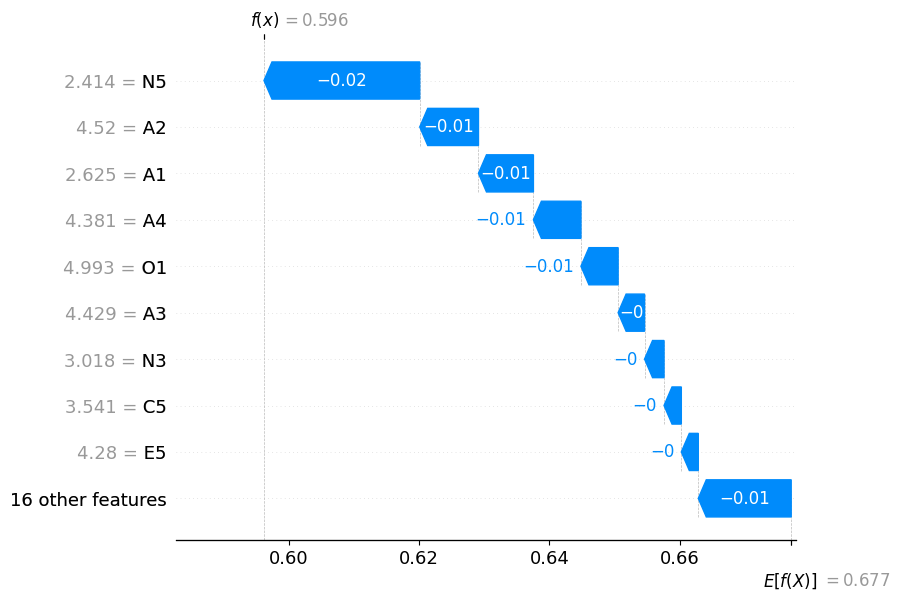

In [80]:
shap.plots.waterfall(exp)

In [81]:
exp1 = shap.Explanation(shap_values_chrts[1])
exp1.base_values = base_values_chrt[1]
exp1.data = np.nanmean(data_each_chrt[1], axis=0)
exp1.feature_names = clf.feature_names_in_

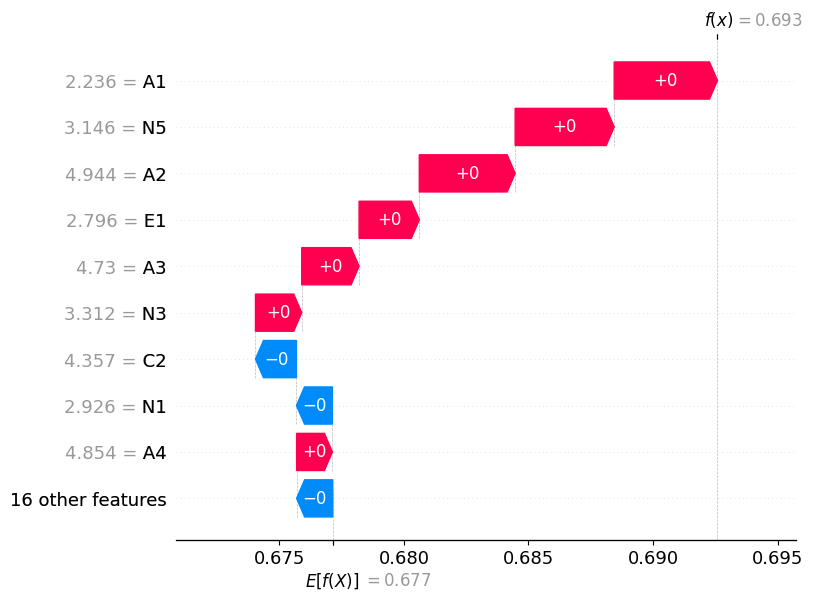

In [82]:
shap.plots.waterfall(exp1)

In [1]:
embeddings.head()

NameError: name 'embeddings' is not defined

- Input parameters
  - Number of groups
  - Name ref variable
  - Name perf variable
 

- Options
  - Tree/graph search problem approach
     - Data structures:
         - Set of visited states
         - Priority queue sorted by minimum fitness function value
         - Attribute to keep the current best visited state
     
     - Initialization:
         - Based on the provided number of groups, obtain n-tiles per ref
         - Obtain mean perf value for each tile for each ref
         - Caclculate the mean perf std deviation of each tile across the refs
         - Fitness function: sum of tiles std. devs

     - Iteration:
         - Select the tile with the largest mean perf variance
         - Generate 2 new states:
           - Observation with highest positive std deviation within the tile*  is assigned to upper tile
           - Observation with lowest (highest negative) std deviation within the tile* is assigned to lower tile
         - Calculate fitness function for each new state
         - Check if new states yield better (lower) fitness function value than current 
         - Add both new states to a priroty queue based on their fitness function value
         - Add current state to visited states set
         - Advance to the (already prioritized) next state on queue

    *obtained by averaging the std dev of each obs across the tiles



  - Linear optimization problem approach
    - Minimize sum of tile's std_dev(X:bad) subject to a reasonable ordination(Y:score) across refs and tiles

- Identificar as vars mais importantes para o modelo como um todo e para os 'hhh'
- Cruzamento do nosso GH com o Meridian, da Classificação deles com o Meridian e do nosso GH com a Classificação deles (fácil de fazer com pd.crosstab; ou talvez groupby, calculando a média da inad.)

- Validando a marcação do target
  - Volumetria do target por safra
  - Crosstab classificacao por safra
  - *Tabela: ref X mau_mob3_ref0, virou_ddd_m1, virou_ddd_m2, virou_ddd_m3, soma_ddd
  - Ordenacao do score do modelo
    - Bad (espec 'ddd' em mob3) por classificacao politicas
    - Bad (espec 'ddd' em mob3) por FPD15


- Validando o modelo
    - Ordenacao do score do modelo
        - Decil score do modelo por FPD15

  - Cruzamentos com o rating especialista
      - Rating políticas VS GHs
      - Rating políticas VS decis score modelo
        - Cabe estudo de matriz confusao adotando diferentes decis como threshold
        - *Além dos ratings politicas, criar novas linhas: hhh_virou_XXX_m1, hhh_virou_XXX_m2, hhh_virou_XXX_m3, para entender como os Hs estao sendo classificados pelo modelo de acordo com sua transicao para o 1o rating

  - Público H
    - Valores de Gini
      - Todos Hs: treino e teste
      - Hs com transicao em m_1: treino e teste
      - Hs com transicao em m_2: treino e teste
      - Hs com transicao em m_3: treino e teste
    - Shap Values para publico H e nao H

  - Público D
     - Constroi a var tempo_ddd, agrupa por classificacao_cmrcl e tempo_ddd e cruza pelos decis do modelo. Unstack em tempo ddd (colunas viram multiindex com (decil_modelo, tempo_ddd)); talvez tb agrupa por classificacao_cmrcl, decil e tempo_ddd  

In [ ]:
# Validando marcacao do target

full_table['classificacao_cmrcl_m1'] = full_table.sort_values('safra').groupby('cnpj_espec').classificacao_cmrcl.shift(-1)
full_table['classificacao_cmrcl_m1'] = full_table.sort_values('safra').groupby('cnpj_espec').classificacao_cmrcl.shift(-2)
full_table['classificacao_cmrcl_m1'] = full_table.sort_values('safra').groupby('cnpj_espec').classificacao_cmrcl.shift(-3)

cond1 = full_table.classificacao_cmrcl_m1 == 'ddd'
cond2 = (full_table.classificacao_cmrcl_m1 != 'ddd') & (full_table.classificacao_cmrcl_m2 == 'ddd')
cond3 = (full_table.classificacao_cmrcl_m1 != 'ddd') & (full_table.classificacao_cmrcl_m2 != 'ddd') & (full_table.classificacao_cmrcl_m3 == 'ddd')

#full_table['mau_mob3_m0'] = full_table.mau_mob3 
full_table['virou_ddd_m1'] = np.where(cond1, 1, 0)
full_table['virou_ddd_m2'] = np.where(cond2, 1, 0)
full_table['virou_ddd_m3'] = np.where(cond3, 1, 0)

agg_mau_mob3 = full_table.groupby('safra').mau_mob3.sum() 
agg_safra_1 = full_table.groupby('safra').virou_ddd_m1.sum()
agg_safra_2 = full_table.groupby('safra').virou_ddd_m2.sum()
agg_safra_3 = full_table.groupby('safra').virou_ddd_m3.sum()
soma_agg_safra = agg_safra_1.add(agg_Safra_2, fill_value=0).add(agg_Safra_3, fill_value=0)

pd.DataFrame({'mau_mob3_m0': agg_mau_mob3,
              'virou_ddd_m1': agg_safra_1,
              'virou_ddd_m2': agg_safra_2,
              'virou_ddd_m3': agg_safra_3,
              'total_ddd_m3': soma_agg_safra})

In [ ]:
# Avaliacao do modelo - Ratings politicas vs decis modelo
list_classfcs = list(full_table.classificacao_cmrcl.unique())


full_table['transicao_hhh'] = np.nan
conditions = []
choices = []
for clss in tqdm(list_classfcs):
    cond1 = (full_table.classificacao_cmrcl == 'hhh') & (full_table.classificacao_cmrcl_m1 == clss) 
    cond2 = (full_table.classificacao_cmrcl_m1 == 'hhh') & (full_table.classificacao_cmrcl_m2 == clss)
    cond3 = (full_table.classificacao_cmrcl_m2 == 'hhh') & (full_table.classificacao_cmrcl_m3 == clss)
    
    conditions.append(cond1)
    conditions.append(cond2)
    conditions.append(cond3)

    choices.append(f'hhh_virou_{clss}_m1')
    choices.append(f'hhh_virou_{clss}_m2')
    choices.append(f'hhh_virou_{clss}_m3')


full_table['transicao_hhh'] = np.select(conditions,choices,default=np.nan)

pd.crosstab(full_table.transicao_hhh, full_table.score_decile)

Lembrar de:
    - Checar as observacoes com claf_0 em branco
    - Fazer validacao flat table
        - Variance Threshold após normalizacao
        - Cálculo de correlacao com eliminacao da var com maior soma de correlacao com as demais
        - Validar que todos os passam usam os mesmos conceitos para:
            - Divisao dos grupos de treino, valid, teste...
        - Validar a sequencia de m_1, m_2 e m_3 garantindo que exista somente 1m estre eles

In [6]:
import ipywidgets as widgets

In [8]:
widgets.IntSlider()

IntSlider(value=0)

In [9]:
out = widgets.Output(layout={'border': '1px solid black'})
out

Output(layout=Layout(border_bottom='1px solid black', border_left='1px solid black', border_right='1px solid b…

In [10]:
with out:
    for i in range(10):
        print(i, 'Hello world!')

In [17]:
with out:
    display(embeddings.head(5))

# Widget matriz confusao

In [208]:
embeddings = pd.read_csv('bfi.csv')

In [209]:
embeddings = embeddings.loc[:10,'A1':'C4']

In [210]:
embeddings

,A1,A2,A3,A4,A5,C1,C2,C3,C4
0,2.0,4.0,3.0,4.0,4.0,2.0,3.0,3.0,4.0
1,2.0,4.0,5.0,2.0,5.0,5.0,4.0,4.0,3.0
2,5.0,4.0,5.0,4.0,4.0,4.0,5.0,4.0,2.0
3,4.0,4.0,6.0,5.0,5.0,4.0,4.0,3.0,5.0
4,2.0,3.0,3.0,4.0,5.0,4.0,4.0,5.0,3.0
5,6.0,6.0,5.0,6.0,5.0,6.0,6.0,6.0,1.0
6,2.0,5.0,5.0,3.0,5.0,5.0,4.0,4.0,2.0
7,4.0,3.0,1.0,5.0,1.0,3.0,2.0,4.0,2.0
8,4.0,3.0,6.0,3.0,3.0,6.0,6.0,3.0,4.0
9,2.0,5.0,6.0,6.0,5.0,6.0,5.0,6.0,2.0


In [211]:
#def calculate_error_rate(n):
    
n=2
def paint_columns(s, props):
    if s.name in [col for col in list(embeddings.columns)[-n:]]:
        st = props
    else:
        st = ''
    return (s.shape[0])*[st]

embeddings.style.apply(paint_columns, props='color:white;background-color:darkblue', axis=0)

,A1,A2,A3,A4,A5,C1,C2,C3,C4
0,2.000000,4.000000,3.000000,4.000000,4.000000,2.000000,3.000000,3.000000,4.000000
1,2.000000,4.000000,5.000000,2.000000,5.000000,5.000000,4.000000,4.000000,3.000000
2,5.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,2.000000
3,4.000000,4.000000,6.000000,5.000000,5.000000,4.000000,4.000000,3.000000,5.000000
4,2.000000,3.000000,3.000000,4.000000,5.000000,4.000000,4.000000,5.000000,3.000000
5,6.000000,6.000000,5.000000,6.000000,5.000000,6.000000,6.000000,6.000000,1.000000
6,2.000000,5.000000,5.000000,3.000000,5.000000,5.000000,4.000000,4.000000,2.000000
7,4.000000,3.000000,1.000000,5.000000,1.000000,3.000000,2.000000,4.000000,2.000000
8,4.000000,3.000000,6.000000,3.000000,3.000000,6.000000,6.000000,3.000000,4.000000
9,2.000000,5.000000,6.000000,6.000000,5.000000,6.000000,5.000000,6.000000,2.000000


In [212]:
n = 2

class_neg_politicas = [10]
class_pos_politicas = [idx for idx in list(embeddings.index) if idx not in class_neg_politicas]
class_neg_modelo = list(embeddings.columns)[-n:]
class_pos_modelo = list(embeddings.columns)[:-n]

#np.sum(embeddings.loc[10].values)
class_neg_politicas, class_pos_politicas, class_neg_modelo, class_pos_modelo

([10],
 [0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 ['C3', 'C4'],
 ['A1', 'A2', 'A3', 'A4', 'A5', 'C1', 'C2'])

In [213]:
tp = embeddings.loc[class_pos_politicas,class_pos_modelo].values.sum() # TRUE POSITIVE
tn = embeddings.loc[class_neg_politicas,class_neg_modelo].values.sum() # TRUE NEGATIVE
fp = embeddings.loc[class_neg_politicas,class_pos_modelo].values.sum() # FALSE POSITIVE
fn = embeddings.loc[class_pos_politicas,class_neg_modelo].values.sum() # FALSE NEGATIVE
total = embeddings.values.sum()

In [215]:
print(f'Porcentagem total de acerto = {(tp+tn)/total}')
print(f'Porcentagem total de erro = {(fp+fn)/total}')

print(f'Porcentagem de acerto espec. D = {tn/(tn+fp)}')
print(f'Porcentagem de espec D classificado como ñ D = {fp/(fp+tn)}')

print(f'Porcentagem de acerto espec. ñ D = {tp/(tp+fn)}')
print(f'Porcentagem de espec ñ D classificado como D = {fn/(fn+tp)}')

Porcentagem total de acerto = 0.7475
Porcentagem total de erro = 0.2525
Porcentagem de acerto espec. D = 0.20512820512820512
Porcentagem de espec D classificado como ñ D = 0.7948717948717948
Porcentagem de acerto espec. ñ D = 0.8060941828254847
Porcentagem de espec ñ D classificado como D = 0.19390581717451524


In [216]:
df = pd.DataFrame([[tp, fn],[fp, tn]],
                  index=pd.Index(['Espec. ñ D (Positivo)', 'Espec D (Negativo)'], name='Marcação Políticas:'),
                  columns=pd.Index(['Espec. ñ D', 'Espec D'], name='Marcação Modelo:'))
df#.style

Marcação Modelo:,Espec. ñ D,Espec D
Marcação Políticas:,,
Espec. ñ D (Positivo),291.0,70.0
Espec D (Negativo),31.0,8.0


In [222]:
import seaborn as sns

In [304]:
data = embeddings.astype(int)

In [335]:
from ipywidgets import GridspecLayout, Layout, SelectionSlider
from functools import partial

slider = widgets.SelectionSlider(
    options=['0','1','2','3','4','5','6','7','8','9'],
    value='0',
    description='Decis negativos:',
    disabled=False,
    continuous_update=False,
    orientation='horizontal',
    readout=True,
    readout_format='d',
    layout=Layout(height='100%', width='auto'),
    style={'description_width': 'initial'}
)



def set_label_values(cm_values):
    items = []

    style0={'font_weight': 'bold', 'font_size': '1.2em', 'text_color': 'green'}
    items.append(widgets.Label('Porcentagem total de acerto = {0:.2f}%'.format(0 if cm_values['total'] == 0 else 100*(cm_values['tp']+cm_values['tn'])/cm_values['total']),
                               style=style0))
    
    style1={'font_weight': 'normal', 'font_size': '0.9em', 'text_color': 'green'}
    items.append(widgets.Label('Porcentagem de acerto espec. D = {0:.2f}%'.format(0 if (cm_values['tn']+cm_values['fp']) == 0 else 100*cm_values['tn']/(cm_values['tn']+cm_values['fp'])),
                               style=style1))
    
    items.append(widgets.Label('Porcentagem de acerto espec. ñ D = {0:.2f}%'.format(0 if (cm_values['tp']+cm_values['fn']) == 0 else 100*cm_values['tp']/(cm_values['tp']+cm_values['fn'])),
                               style=style1))
    
    style2={'font_weight': 'bold', 'font_size': '1.2em', 'text_color': 'red'}
    items.append(widgets.Label('Porcentagem total de erro = {0:.2f}%'.format(0 if cm_values['total'] == 0 else 100*(cm_values['fp']+cm_values['fn'])/cm_values['total']),
                               style=style2))

    style3={'font_weight': 'normal', 'font_size': '0.9em', 'text_color': 'red'}
    items.append(widgets.Label('Porcentagem de espec D classificado como ñ D = {0:.2f}%'.format(0 if (cm_values['fp']+cm_values['tn']) == 0 else 100*cm_values['fp']/(cm_values['fp']+cm_values['tn'])),
                               style=style3))
    items.append(widgets.Label('Porcentagem de espec ñ D classificado como D = {0:.2f}%'.format(0 if (cm_values['fn']+cm_values['tp']) == 0 else 100*cm_values['fn']/(cm_values['fn']+cm_values['tp'])),
                               style=style3))
    return items



def paint_columns(s, props, n=0, df_col_list=[]):
    if n == 0:
        st=''
    elif s.name in [col for col in df_col_list[-n:]]:
        st = props
    else:
        st = ''
    return (s.shape[0])*[st]



def obtain_confusion_matrix(source_df, n):
    if n == 0:
        tp, tn, fp, fn, total = (0,0,0,0,0)
    else:
        class_neg_politicas = [10]
        class_pos_politicas = [idx for idx in list(source_df.index) if idx not in class_neg_politicas]
        class_neg_modelo = list(source_df.columns)[-n:]
        class_pos_modelo = list(source_df.columns)[:-n]
    
        tp = source_df.loc[class_pos_politicas,class_pos_modelo].values.sum() # TRUE POSITIVE
        tn = source_df.loc[class_neg_politicas,class_neg_modelo].values.sum() # TRUE NEGATIVE
        fp = source_df.loc[class_neg_politicas,class_pos_modelo].values.sum() # FALSE POSITIVE
        fn = source_df.loc[class_pos_politicas,class_neg_modelo].values.sum() # FALSE NEGATIVE
        total = source_df.values.sum()

    df = pd.DataFrame([[tp, fn],[fp, tn]],
                      index=pd.Index(['Espec. ñ D (Positivo)', 'Espec D (Negativo)'], name='Marcação Políticas:'),
                      columns=pd.Index(['Espec. ñ D', 'Espec D'], name='Marcação Modelo:'))
    
    cm_counts = [tp,tn,fp,fn,total]
    cm_counts_names = ['tp','tn','fp','fn','total']
    cm_values = {k:v for k,v in zip(cm_counts_names, cm_counts)}
    
    return df, cm_values
    

    
def on_value_change(change):
    n = int(change['new'])

    paint_columns_partial = partial(paint_columns, n=n ,df_col_list=list(data.columns))

    cm, cm_values = obtain_confusion_matrix(data, n)

    items = set_label_values(cm_values)

    with output:
        output.clear_output()
        display(data.style.set_table_attributes('width=100%')\
                .apply(paint_columns_partial, props='background:rgba(255,0,0,0.2);', axis=0)\
                .apply_index(lambda s: s.shape[0]*[''] if n == 0 else np.where(s.isin([col for col in list(data.columns)[-n:]]), 'background:rgba(255,0,0,0.2);', ''), axis=1))
    
    with output2:
        output2.clear_output()
        display(cm)
    
    with output3:
        output3.clear_output()
        upper_box = widgets.VBox([items[0], items[1], items[2]])
        lower_box = widgets.VBox([items[3], items[4], items[5]])
        display(widgets.HBox([upper_box, lower_box]))

slider.observe(on_value_change, names='value')

In [352]:
# def create_expanded_button(description, button_style):
#     return Button(description=description, button_style=button_style, layout=Layout(height='auto', width='auto'))
output = widgets.Output(layout=Layout(height='auto', width='auto'), clear=True)
with output:
    paint_columns_partial = partial(paint_columns, n=0 ,df_col_list=list(data.columns))
    display(data.style.set_table_attributes('width=100%').apply(paint_columns_partial, props='background:rgba(255,0,0,0.2);', axis=0))

cm, cm_values = obtain_confusion_matrix(data, 0)
output2 = widgets.Output(layout=Layout(display='grid', justify_content='center', align_content='flex-end',height='auto', width='auto'), clear=True)
with output2:
    display(cm)

output3 = widgets.Output(layout=Layout(display='grid', justify_content='center',  height='auto', width='auto'), clear=True)
with output3:
    items = set_label_values(cm_values)
    upper_box = widgets.VBox([items[0], items[1], items[2]])
    lower_box = widgets.VBox([items[3], items[4], items[5]])
    display(widgets.HBox([upper_box, lower_box]))

output4 = widgets.Output(layout=Layout(display='grid', align_content='center',height='auto', width='auto'), clear=True)
with output4:
    display(slider)

            
grid = GridspecLayout(6, 12, height='450px', place_items='center', place_contents='center')

grid[:5, :6] = output
grid[5:6, :6] = output4

grid[:3, 6:] = output2
grid[3:, 6:] = output3
grid

GridspecLayout(children=(Output(layout=Layout(grid_area='widget001', height='auto', width='auto')), Output(lay…

In [ ]:
font_weight
font_size
text

In [274]:
items[0].style.keys

['_model_module',
 '_model_module_version',
 '_model_name',
 '_view_count',
 '_view_module',
 '_view_module_version',
 '_view_name',
 'background',
 'description_width',
 'font_family',
 'font_size',
 'font_style',
 'font_variant',
 'font_weight',
 'text_color',
 'text_decoration']

In [279]:
items[0].style.__dict__

{'_trait_values': {'_model_module': '@jupyter-widgets/controls',
  '_model_module_version': '2.0.0',
  '_model_name': 'LabelStyleModel',
  '_view_count': None,
  '_view_module': '@jupyter-widgets/base',
  '_view_module_version': '2.0.0',
  '_view_name': 'StyleView',
  'background': None,
  'comm': <ipykernel.comm.comm.BaseComm at 0x7f45fb0ce6f0>,
  'description_width': '',
  'font_family': None,
  'font_size': None,
  'font_style': None,
  'font_variant': None,
  'font_weight': None,
  'text_decoration': None,
  'keys': ['_model_module',
   '_model_module_version',
   '_model_name',
   '_view_count',
   '_view_module',
   '_view_module_version',
   '_view_name',
   'background',
   'description_width',
   'font_family',
   'font_size',
   'font_style',
   'font_variant',
   'font_weight',
   'text_color',
   'text_decoration'],
  'text_color': None},
 '_trait_notifiers': {'comm': {'change': [<traitlets.traitlets.ObserveHandler at 0x7f461c5e9f10>]}},
 '_trait_validators': {},
 '_cross_v